In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import os

os.chdir(r"C:\Users\chris\OneDrive\Bureau\Projets\treasury-basis-trading")
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))

from treasury_basis.bond_pricing import (
    price_bond_simple, accrued_interest, dv01, calcul_cf
)
from treasury_basis.futures import (
    futures_quoted_price, identifier_ctd_avec_recalibrage
)
from treasury_basis.basis import gross_basis, carry, net_basis, implied_repo_rate
from treasury_basis.strategy import calculate_zscore, generate_signals, calculate_pnl
from treasury_basis.risk import (
    sharpe_ratio, max_drawdown, calmar_ratio, win_rate,
    performance_summary, sensitivity_analysis, stress_test
)

# Charger les données FRED
df = pd.read_csv(
    "data/processed/treasury_rates.csv",
    index_col=0,
    parse_dates=True
)
df["financing_rate"] = df["sofr"].fillna(df["effr"])

rate = df["yield_10Y"].mean() / 100
financing_rate = df["financing_rate"].mean() / 100

print(f"Taux moyen DGS10    : {rate*100:.2f}%")
print(f"Taux de financement : {financing_rate*100:.2f}%")

Taux moyen DGS10    : 2.31%
Taux de financement : 1.56%


In [2]:
# Panier d'obligations
obligations = pd.DataFrame({
    "nom":         ["OBL_A", "OBL_B", "OBL_C", "OBL_D", "OBL_E", "OBL_F"],
    "coupon_rate": [0.020,   0.040,   0.060,   0.075,   0.090,   0.110  ],
    "periods":     [13,      17,      19,      20,      21,      22     ],
})
obligations["CF"] = obligations.apply(
    lambda row: calcul_cf(row["coupon_rate"], row["periods"]), axis=1
)

# Paramètres communs
face = 100
days_since_coupon = 90
days_in_period = 182
days_to_next_coupon = 92
days_to_delivery = 180

# Reconstruire la série de basis sur les données FRED réelles
yields_reels = df["yield_10Y"].dropna() / 100
dates = yields_reels.index

print("Calcul du basis sur la série historique...")
gross_basis_series = []

for y in yields_reels:
    df_y = identifier_ctd_avec_recalibrage(
        obligations, rate=y,
        days_since_coupon=days_since_coupon,
        days_to_next_coupon=days_to_next_coupon,
        days_to_delivery=days_to_delivery,
        days_in_period=days_in_period,
        face=face
    )
    ctd_row = df_y[df_y["is_CTD"]].iloc[0]
    gb = gross_basis(ctd_row["p_clean"], ctd_row["F"], ctd_row["CF"])
    gross_basis_series.append(gb)

basis_series = pd.Series(gross_basis_series, index=dates, name="gross_basis")
print("Calcul terminé.")

# Générer les signaux avec le seuil optimal trouvé en semaine 4
zscore = calculate_zscore(basis_series, window=60)
signals = generate_signals(zscore, entry_threshold=3.0, exit_threshold=0.5)
results = calculate_pnl(
    basis_series, signals,
    nominal=1_000_000,
    transaction_cost_bps=2.0
)

print(f"\nBasis reconstruit sur {len(basis_series)} jours ouvrés.")

Calcul du basis sur la série historique...
Calcul terminé.

Basis reconstruit sur 2009 jours ouvrés.


In [3]:
# Calcul du taux sans risque moyen sur la période
risk_free = df["financing_rate"].dropna().mean() / 100

metrics = performance_summary(
    results["pnl_daily"],
    results["pnl_cumulative"],
    signals,
    risk_free_rate=risk_free
)

print("=" * 45)
print("PERFORMANCE DE LA STRATÉGIE BASIS TRADING")
print("=" * 45)
print(f"  P&L total          : ${metrics['pnl_total']:>12,.2f}")
print(f"  Sharpe ratio       : {metrics['sharpe_ratio']:>12.3f}")
print(f"  Maximum drawdown   : ${metrics['max_drawdown']:>12,.2f}")
print(f"  Calmar ratio       : {metrics['calmar_ratio']:>12.3f}")
print(f"  Win rate           : {metrics['win_rate']*100:>11.1f}%")
print(f"  Nombre de trades   : {metrics['n_trades']:>12}")
print(f"  Jours en position  : {metrics['jours_en_position']:>12}")
print("=" * 45)
print()
print("Note : résultats basés sur des prix simulés.")
print("À interpréter comme une démonstration méthodologique,")
print("pas comme une performance réelle attendue.")

PERFORMANCE DE LA STRATÉGIE BASIS TRADING
  P&L total          : $    5,692.36
  Sharpe ratio       :        0.148
  Maximum drawdown   : $  -18,894.25
  Calmar ratio       :        0.038
  Win rate           :        41.9%
  Nombre de trades   :           22
  Jours en position  :          288

Note : résultats basés sur des prix simulés.
À interpréter comme une démonstration méthodologique,
pas comme une performance réelle attendue.


Analyse de sensibilité en cours...

Top 10 combinaisons par Sharpe ratio :

 entry_threshold  exit_threshold  pnl_total  sharpe_ratio  max_drawdown  win_rate  n_trades
             3.5            1.00   19327.83         3.324      -1055.49     0.484         8
             3.5            0.75   17053.92         2.049      -2996.47     0.475         8
             3.0            1.00   27339.92         1.645      -7170.08     0.395        26
             3.0            0.75   24839.81         1.279      -8092.98     0.414        24
             2.5            1.00   29888.14         1.024     -19030.06     0.345        86
             2.5            0.75   27488.82         0.835     -21245.23     0.372        84
             3.5            0.50   15259.36         0.629     -18894.25     0.459         8
             3.5            0.25   14764.37         0.555     -18894.25     0.443         7
             2.0            1.00    8702.90         0.190     -55993.33     0.234       266
    

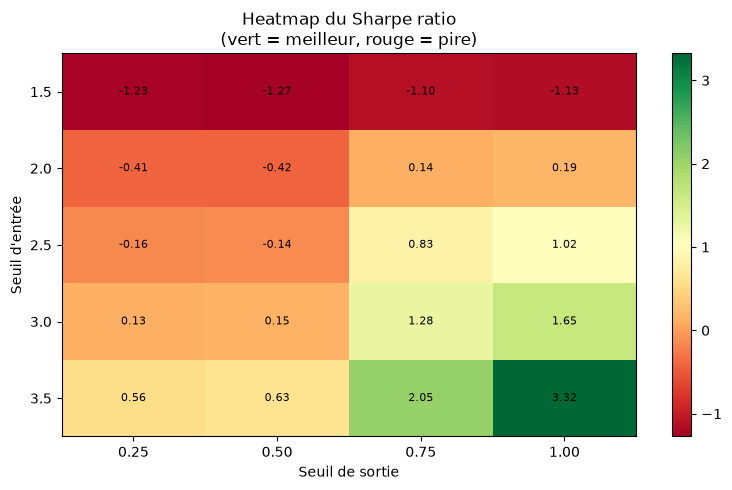

In [5]:
# Tester toutes les combinaisons de seuils
entry_thresholds = [1.5, 2.0, 2.5, 3.0, 3.5]
exit_thresholds = [0.25, 0.5, 0.75, 1.0]

print("Analyse de sensibilité en cours...")
df_sensitivity = sensitivity_analysis(
    basis=basis_series,
    entry_thresholds=entry_thresholds,
    exit_thresholds=exit_thresholds,
    nominal=1_000_000,
    transaction_cost_bps=2.0,
    zscore_window=60
)

print("\nTop 10 combinaisons par Sharpe ratio :")
print()
cols = ["entry_threshold", "exit_threshold", "pnl_total",
        "sharpe_ratio", "max_drawdown", "win_rate", "n_trades"]
print(df_sensitivity[cols].sort_values("sharpe_ratio", ascending=False).head(10).to_string(index=False))

# Heatmap du Sharpe ratio
pivot = df_sensitivity.pivot_table(
    values="sharpe_ratio",
    index="entry_threshold",
    columns="exit_threshold"
)

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(pivot.values, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([f"{x:.2f}" for x in pivot.columns])
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels([f"{y:.1f}" for y in pivot.index])
ax.set_xlabel("Seuil de sortie")
ax.set_ylabel("Seuil d'entrée")
ax.set_title("Heatmap du Sharpe ratio\n(vert = meilleur, rouge = pire)")
plt.colorbar(im, ax=ax)

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val = pivot.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                    fontsize=8, color="black")

plt.tight_layout()
plt.show()

In [10]:
# Scénarios de stress
scenarios = {
    "Basis +50bp":           0.50,   # élargissement brutal du basis
    "Basis -50bp":          -0.50,   # compression brutale du basis
    "Basis +100bp":          1.00,   # crise de liquidité
    "Basis -100bp":         -1.00,   # flight to quality
    "Choc 2020 COVID":       0.75,   # calibré sur l'élargissement mars 2020
    "Choc 2022 hausse Fed": -0.60,   # calibré sur la compression 2022
}

df_stress = stress_test(
    basis=basis_series,
    signals=signals,
    scenarios=scenarios,
    nominal=1_000_000
)

print("Résultats des stress tests :")
print()
print(df_stress.to_string(index=False))
print()
print("Interprétation :")
print("Un élargissement du basis (+) est favorable si on est long basis.")
print("Une compression (-) est favorable si on est short basis.")
print("L'impact dépend de la position dominante dans la stratégie.")

Résultats des stress tests :

            scenario  choc_basis  pnl_total  max_drawdown
         Basis +50bp        0.50    5692.36     -18894.25
         Basis -50bp       -0.50    5692.36     -18894.25
        Basis +100bp        1.00    5692.36     -18894.25
        Basis -100bp       -1.00    5692.36     -18894.25
     Choc 2020 COVID        0.75    5692.36     -18894.25
Choc 2022 hausse Fed       -0.60    5692.36     -18894.25

Interprétation :
Un élargissement du basis (+) est favorable si on est long basis.
Une compression (-) est favorable si on est short basis.
L'impact dépend de la position dominante dans la stratégie.
